# Room Simulation: Late Reverb from Decaying Noise

*Fabian Brinkmann*<br>  
*Audio Communication Group, Technische Universität Berlin*<br>  
*Contact: fabian.brinkmann@tu-berlin.de*

In this task you will generate exponentially decaying noise with frequency dependent decay times and binaural diffuse-field coherence. This is a simple means to simulate stochastic late diffuse reverb for room acoustical simulations.

The late reverb will look similar as the one shown in the image below

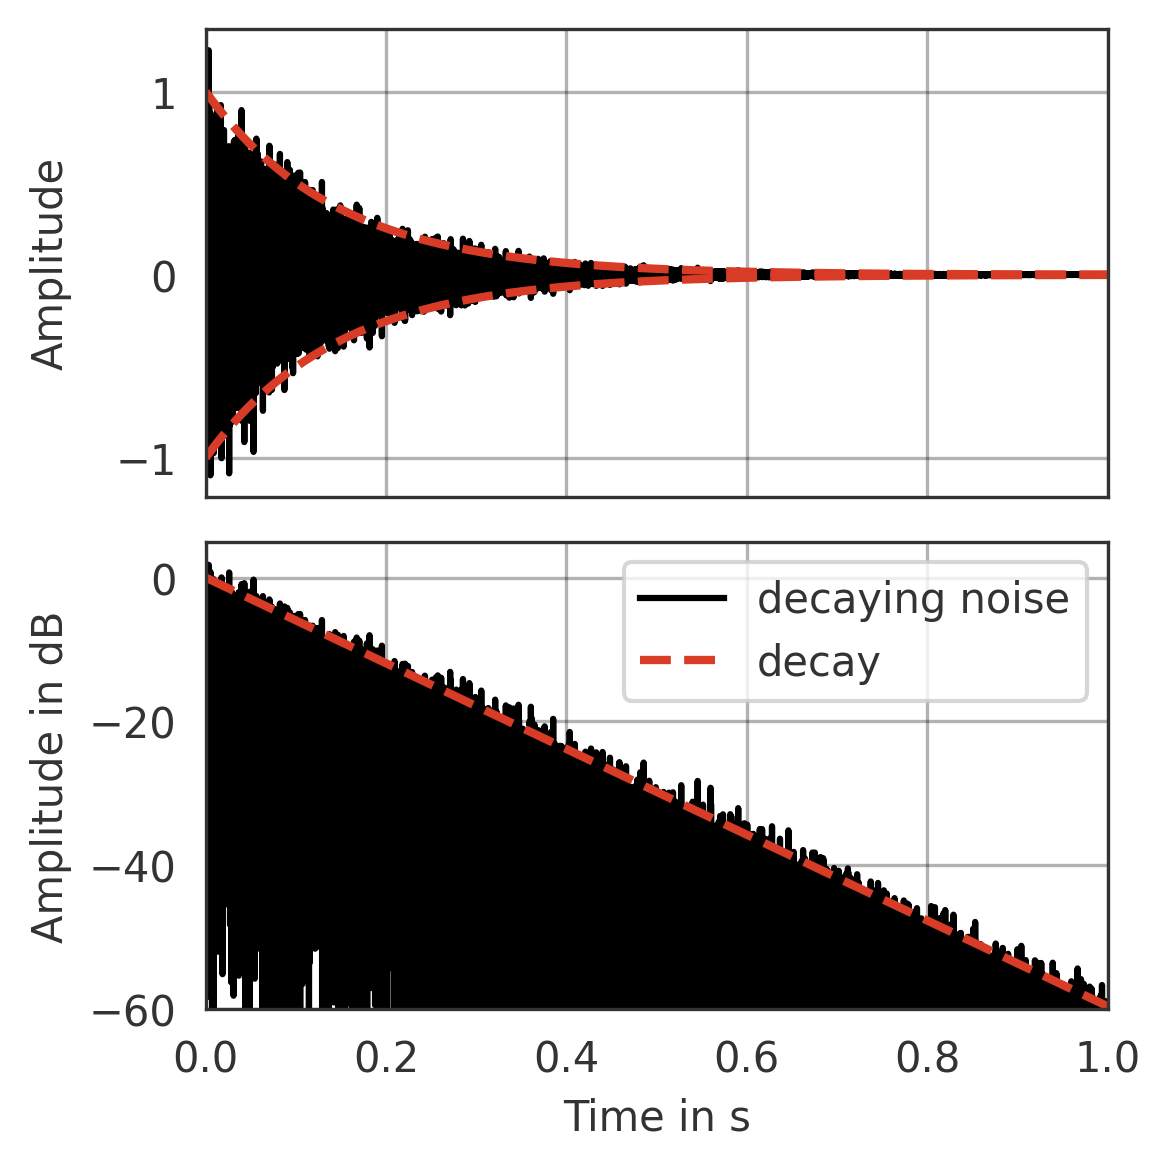

The block diagram below shows that the algorithm takes to independent white noise signals as input and that the decaying noise is designed in three steps:

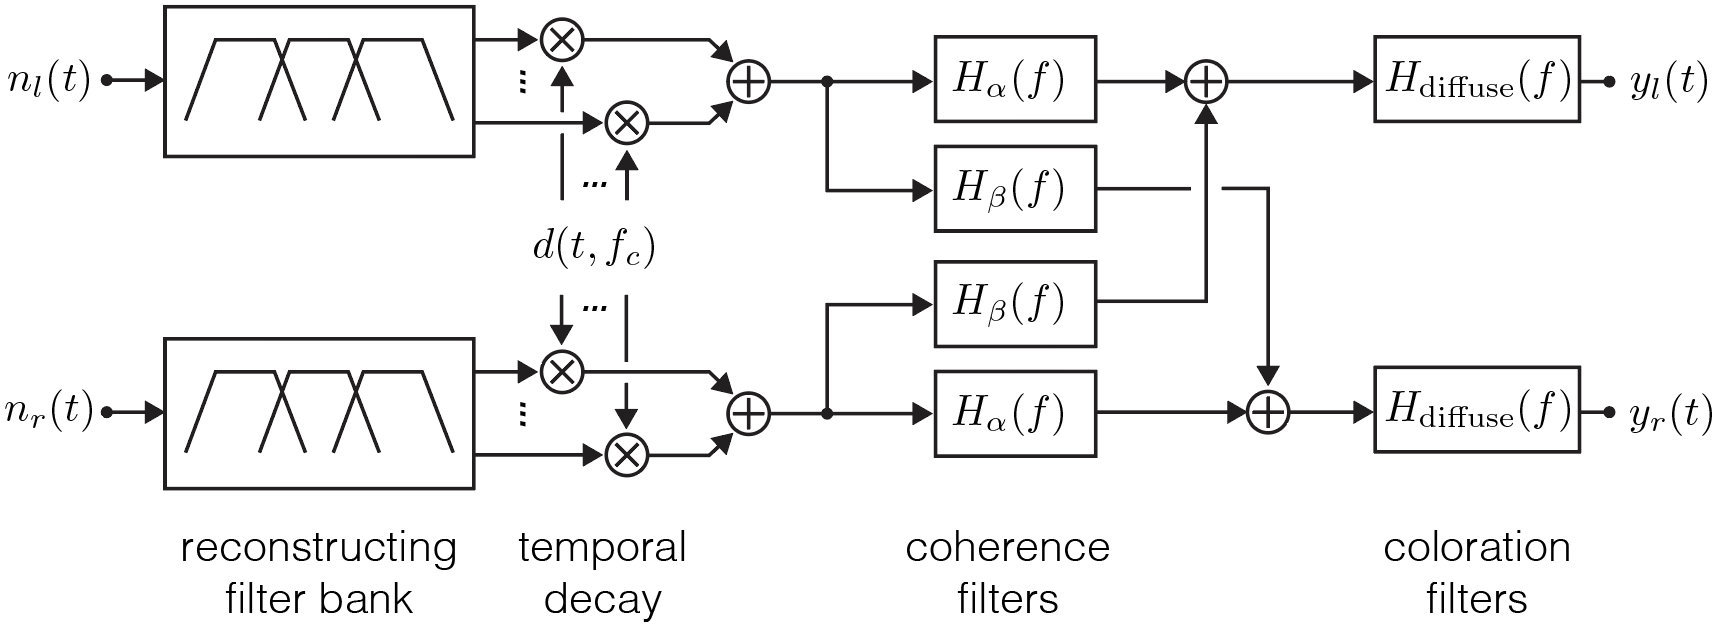

In the first step, the two noise signals are filtered into octave or fractional octave bands, a frequency dependent exponential decay is applied, and the (fractional) octave band signals are summed to obtain a broad-band decaying noise signal. In the second step, the coherence of the noise signals is manipulated to match those of binaural signals under diffuse field conditions. In the third step, an optional diffuse field coloration is applied to account for the sound color of the source and receiver.

**Duration:** 60-120 Minutes

**Requirements:** Basic knowledge of binaural hearing, digital filters, artificial reverbs, and digital signal processing

**References**<br>  
[1] C. Borß and R. Martin, “An improved parametric model for perception-based design of virtual acoustics,” in AES 35th International Conference, London, UK, Feb. 2009.


**Dependencies**<br>  
`pip install pyfar>=0.8 sofar nbgrader ipykernel watermark pooch`

In [ ]:
import pyfar as pf
import numpy as np
import matplotlib.pyplot as plt
import os
import pooch
from IPython.display import Audio, display
%matplotlib inline

Before starting the assignment, download the binaural diffuse field transfer function (DFTF) for later. This is also referred to as Common Transfer Function (CTF) and is contained in the file `FABIAN_CTF_measured_smoothed.sofa` that is downloaded by executing the cell below.

In [ ]:
# adjust this path to your needs. Using `None` will download the file to your
# system cash.
path = None

# Leave this as it is: This is the URL from which the data will be downloaded
# and a hash for checking if the download worked.
url = 'https://github.com/pyfar/files/raw/refs/heads/main/education/VAR_TUB/FABIAN_CTF_measured_smoothed.sofa?download='
hash = 'a0f5c3c39aa18ffa67463d9f991e5c828582ce68998d3aacde1be2ffb8de0c92'
file_ctf = pooch.retrieve(
    url, hash, fname='FABIAN_CTF_measured_smoothed.sofa', path=path)

### Step 1: Define the scene

Start with the definition of the acoustic constants

In [ ]:
# speed of sound in meters per second
# YOUR CODE HERE
raise NotImplementedError()

# sampling_rate in Hz
# YOUR CODE HERE
raise NotImplementedError()

The reverberation time can be frequency dependent and is commonly defined in octave or third octave bands. Chose a resolution and frequency range for defining the reverberation time below.

In [ ]:
# define the center frequencies of the (fractional) octaves
# YOUR CODE HERE
raise NotImplementedError()

# Define the reverberation time at the center frequencies.
# Typically, the reverberation time decreases with frequency
# YOUR CODE HERE
raise NotImplementedError()

# plot or print the defined reverberation times
# YOUR CODE HERE
raise NotImplementedError()

### Step 2.1: Generate input signals

A binaural reverb requires two independent noise signals as the starting point, denoted $n_l(t)$ and $n_r(t)$ in the figure at the beginning of this notebook.

In [ ]:
# select a reasonable duration for the noise signals
# YOUR CODE HERE
raise NotImplementedError()

# generate white gaussian noise
# YOUR CODE HERE
raise NotImplementedError()

# normalize the signals to a maximum amplitude of 1 (nicer for plotting)
# YOUR CODE HERE
raise NotImplementedError()

# plot the noise signal in the time and frequency domain
# YOUR CODE HERE
raise NotImplementedError()

### Step 2.2: Generate a reconstructing (fractional) octave filter bank

The block diagram for the decaying noise reverb shows that the noise input signals are filtered in (fractional) octave bands that are summed up in a later step. For this to work, we need a reconstructing filter bank, where the sum of the filters equals the input signal.

In [ ]:
# generate a pyfar FilterFIR object containing the reconstructing filter bank
# YOUR CODE HERE
raise NotImplementedError()

To get an impression of the filter bank, get its impulse response by filtering an impulse signal and plot the output as well as the summed output.

**Note:** Carefully check the delay of the filterbank. This must be removed after filtering the noise in the next step.

In [ ]:
# get the impulse response (how long should it be at least?)
# YOUR CODE HERE
raise NotImplementedError()

# sum all filter channels to show that the filter bank is reconstructing
# YOUR CODE HERE
raise NotImplementedError()

# plot the filter bank and the sum of all filters
# in the time and frequency domain
# YOUR CODE HERE
raise NotImplementedError()

### Step 2.3: Apply reconstructing (fractional) octave filter bank

Now filter the noise signal with the filterbank, remove the delay and plot the output again.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

### Step 2.4: Generate the temporal decay

Compute the decay based on the reverberation time $T(f_c)$ and speed of sound $c$. The decay is given by

$d(t, f_c) = \mathrm{e}^{-\delta t}$,

with $\delta = 0.02 \,c/T$, and the (fractional) octave center frequencies $f_c$.

In [ ]:
# generate the decay
# YOUR CODE HERE
raise NotImplementedError()

# plot for visual inspection
# YOUR CODE HERE
raise NotImplementedError()

### Step 2.5: Apply the temporal decay

Apply the decay to the filtered noise signal by a time domain multiplication.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

# plot for visual inspection
# YOUR CODE HERE
raise NotImplementedError()

Sum the filtered noise signal across the channels of the filterbank to yield a noise signal with two channels - one for the left ear and one for the right ear.

In [ ]:
# sum channels
# YOUR CODE HERE
raise NotImplementedError()

# plot time and frequency signal for both channels
# YOUR CODE HERE
raise NotImplementedError()

# Plot spectrogram for first channel.
# If everything worked, you should see the frequency dependent decay.
# YOUR CODE HERE
raise NotImplementedError()

### Step 3: Apply binaural coherence filters

At the moment, the two channels of the decaying noise signal are statistically independent, which means they have a coherence of zero. Binaural signals show a sinc-like coherence under diffuse field conditions, that is, the coherence is large at low frequencies and zero at higher frequencies. To change this, generate and apply the binaural coherence filters. Start with computing and plotting the binaural coherence $\gamma$

$\gamma(f) = \mathrm{sinc}(f / f_0) \cdot \max(0, 1 - f/f_1)$

where f_0 = 550 Hz (hence $\gamma(n f_0) = 0$) and $f_1=2700$ (hence $\gamma(f\geq f_1)=0$).

From this, the coherence filters $H_\alpha$ and $H_\beta$ can be computed as

$H_\beta(f) = \mathrm{sign}(\gamma(f)) \sqrt{0.5 (1 - \sqrt{1 - \gamma^2(f)})}$

and

$H_\alpha(f) = \sqrt{1 - H_\beta^2(f)}\,$.

In [ ]:
# length and frequencies of the coherence filters
n_samples_coherence = 2**12
f = pf.dsp.fft.rfftfreq(n_samples_coherence, sampling_rate)

# compute the coherence
# YOUR CODE HERE
raise NotImplementedError()

# compute coherence filters
# YOUR CODE HERE
raise NotImplementedError()

# plot for visual inspection
# YOUR CODE HERE
raise NotImplementedError()

Now, its time to apply the coherence filters. If you compare the decaying noise with and without coherence filters, you should notice that the left and right ear signals are now more similar to each other at low frequencies.

The block diagram at the beginning of the assignment shows you, how this is done.

In [ ]:
# convert the coherence filters to pyfar signal objects
# YOUR CODE HERE
raise NotImplementedError()

# generate left ear signal
# YOUR CODE HERE
raise NotImplementedError()

# generate right ear signal
# YOUR CODE HERE
raise NotImplementedError()

# combine to two channel binaural signal
# YOUR CODE HERE
raise NotImplementedError()

# plot for visual inspection
# YOUR CODE HERE
raise NotImplementedError()

### Step 4: Apply Diffuse-Field Coloration Filters

The decaying noise has an almost white spectrum at the moment, which is not the case for binaural signals under diffuse-field conditions. To change this, we can apply a binaural diffuse-field transfer function (DFTF). We could additionally apply the diffuse field-transfer function of the source, but we assume the source to have a white spectrum across frequency and space for simplicity.

If you plot the decaying noise after applying the DFTF, you will notice a wide resonance around 4 kHz originating from the pinna.

In [ ]:
# load diffuse field transfer function (the path to the file is stored in the
# variable `file_ctf`)
dftf, *_ = pf.io.read_sofa(file_ctf, verbose=False)

# convolve decaying noise with diffuse field transfer function
# YOUR CODE HERE
raise NotImplementedError()

# plot for visual inspection
# YOUR CODE HERE
raise NotImplementedError()

### Step 5: Listen

The binaural isotropic late reverberation is now finished - so lets listen to the results. Note that listening to the results before applying the diffuse field coloration filter makes probably most sense, because most headphones will have a transfer function that is similar to the applied filter.

In [ ]:
# load an audio content of you choice
content = pf.signals.files.drums(sampling_rate)

# create an audio player for the content
content_player = Audio(content.time, rate=sampling_rate)
display('Anechoic audio content')
display(content_player)


# Auralize a single channel of the decaying noise.
# This equals a isotropic room impulse response (RIR) simulated
# with a single omni-directional microphone
# YOUR CODE HERE
raise NotImplementedError()

# Auralize the binaural decaying noise without diffuse field coherence
# YOUR CODE HERE
raise NotImplementedError()

# Auralize the binaural decaying noise with diffuse field coherence
# YOUR CODE HERE
raise NotImplementedError()

### Step 6: Save

Save the result as a wav-file for later. You will need this again in case you also want to do the assignment on the hybrid room simulation using an image source model for the direct sound and early reflections and the decaying noise for the late reverberation.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

# License notice

This notebook is licensed under CC BY 4.0

# Watermark

The following watermark might help others to install specific package versions that might be required to run the notebook. Please give at least the versions of Python, IPython, numpy , and scipy, major third party packagers (e.g., pytorch), and all used pyfar packages.

In [1]:
%load_ext watermark
%watermark -v -m -p numpy,pyfar,sofar,pooch,nbgrader,watermark

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

numpy    : 2.4.6
pyfar    : 0.8.1
sofar    : 1.3.0
pooch    : 1.9.0
nbgrader : 0.9.5
watermark: 2.6.0

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 25.5.0
Machine     : arm64
Processor   : arm
CPU cores   : 8
Architecture: 64bit

